<a href="https://colab.research.google.com/github/devPartho3/Mern-Stack-Web-Dev-Marathon-/blob/main/Stock_Market_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [31]:
!pip install prophet
!pip install statsmodels
!pip install pystan
import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet
from statsmodels.tsa.seasonal import seasonal_decompose
import numpy as np

In [32]:
df=pd.read_csv('/content/TSLA.csv')
df.head(5)

,Date,Open,High,Low,Close,Adj Close,Volume
0,2010-07-01,5.000,5.184,4.054,4.392,4.392,41094000
1,2010-07-02,4.600,4.620,3.742,3.840,3.840,25699000
2,2010-07-06,4.000,4.000,3.166,3.222,3.222,34334500
3,2010-07-07,3.280,3.326,2.996,3.160,3.160,34608500
4,2010-07-08,3.228,3.504,3.114,3.492,3.492,38557000


In [33]:
#create prophet model
model=Prophet(daily_seasonality=True)

In [34]:
# Prepare the dataframe for Prophet (requires 'ds' and 'y' columns)
prophet_df = df[['Date', 'Close']].rename(columns={'Date': 'ds', 'Close': 'y'})

# Fit the model to the data
model.fit(prophet_df)

In [35]:
#specifying number of dates for prediction
future=model.make_future_dataframe(periods=365)

In [36]:
#Use the model to make predictions
forecast=model.predict(future)

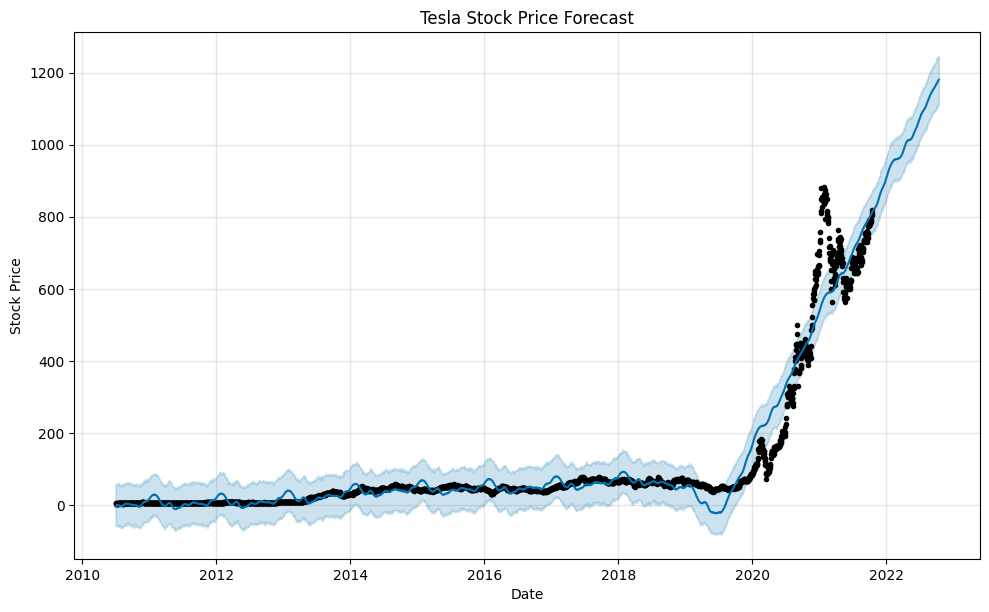

In [37]:
model.plot(forecast)
plt.title('Tesla Stock Price Forecast')
plt.xlabel('Date')
plt.ylabel('Stock Price')
plt.show()

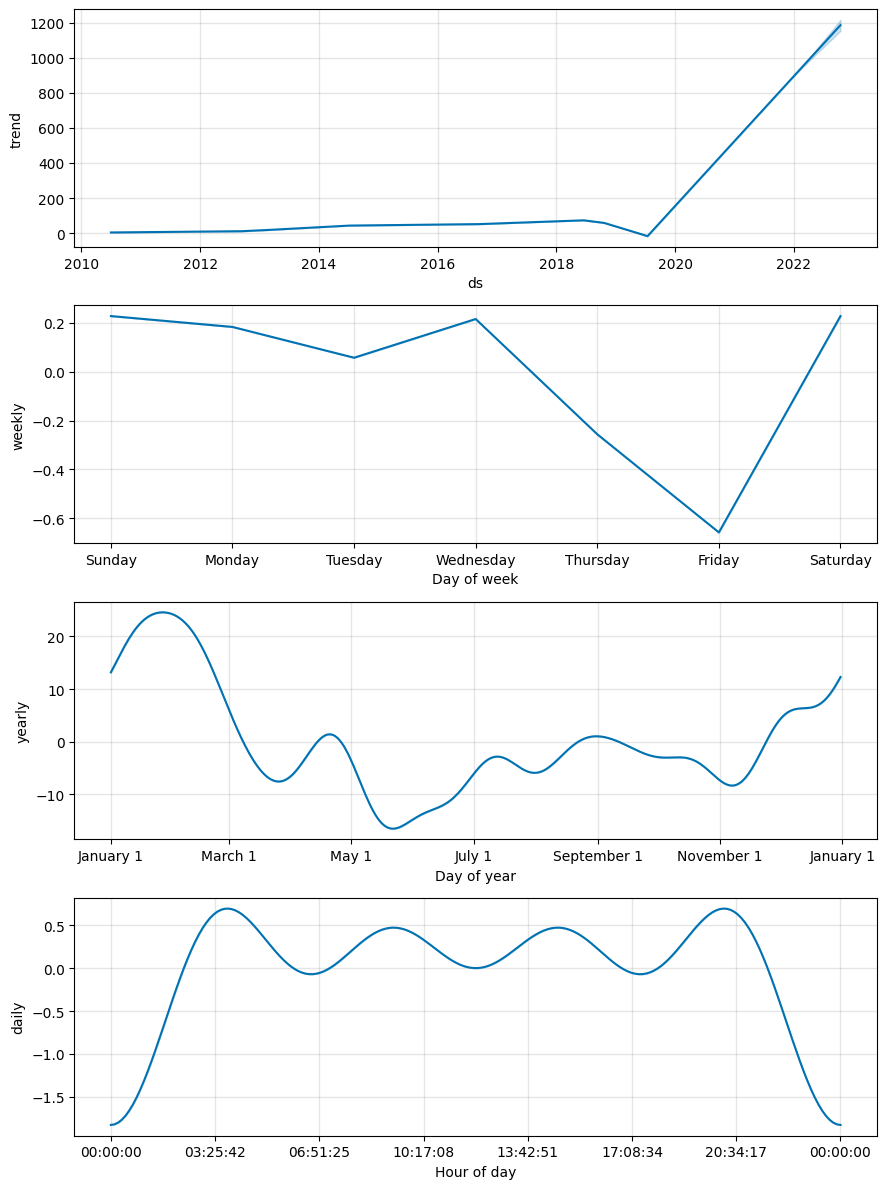

In [38]:
model.plot_components(forecast)
plt.show()

In [44]:
from pandas._libs import missing
#check missing values
missing_values=df.isnull().sum()
print(missing_values)

#basic statistical details
stastics=df.describe()

missing_values.to_csv('missing_values.csv')
stastics.to_csv('stastics.csv')


Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64


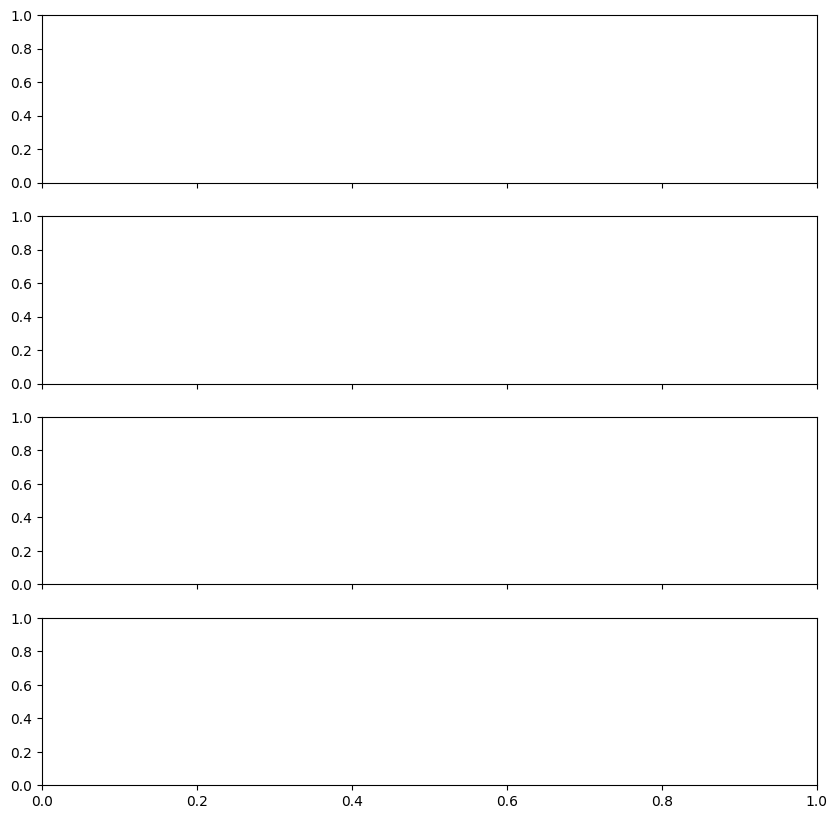

In [49]:
import matplotlib.pyplot as plt
import pandas as pd

# Safely set the date column as index if it's not already set
if 'Date' in df.columns:
    df['Date'] = pd.to_datetime(df['Date'])
    df.set_index('Date', inplace=True)
elif df.index.name != 'Date':
    # If 'Date' is neither a column nor the index, try resetting to locate it
    df = df.reset_index()
    if 'Date' in df.columns:
        df['Date'] = pd.to_datetime(df['Date'])
        df.set_index('Date', inplace=True)

# Ensure the index itself is datetime type
if not isinstance(df.index, pd.DatetimeIndex):
    df.index = pd.to_datetime(df.index)

# Create a figure and set of subplots
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(10, 10), sharex=True)

In [52]:
import matplotlib.pyplot as plt
import pandas as pd
#plot the closing price over time
df['Close'].plot(ax=axes[0],title='Tesla Stock Price')
axes[0].set_ylabel('Closing Price')
axes[0].set_ylabel('Price')


#plot the trading volume over time
df['Volume'].plot(ax=axes[1],title='Tesla Trading Volume')
axes[1].set_ylabel('Trading Volume')
axes[1].set_ylabel('Volume')

#plot the opening price over time
df['Open'].plot(ax=axes[2],title='Tesla Opening Price')
axes[2].set_ylabel('Opening Price')
axes[2].set_ylabel('Price')


Text(24.000000000000007, 0.5, 'Price')

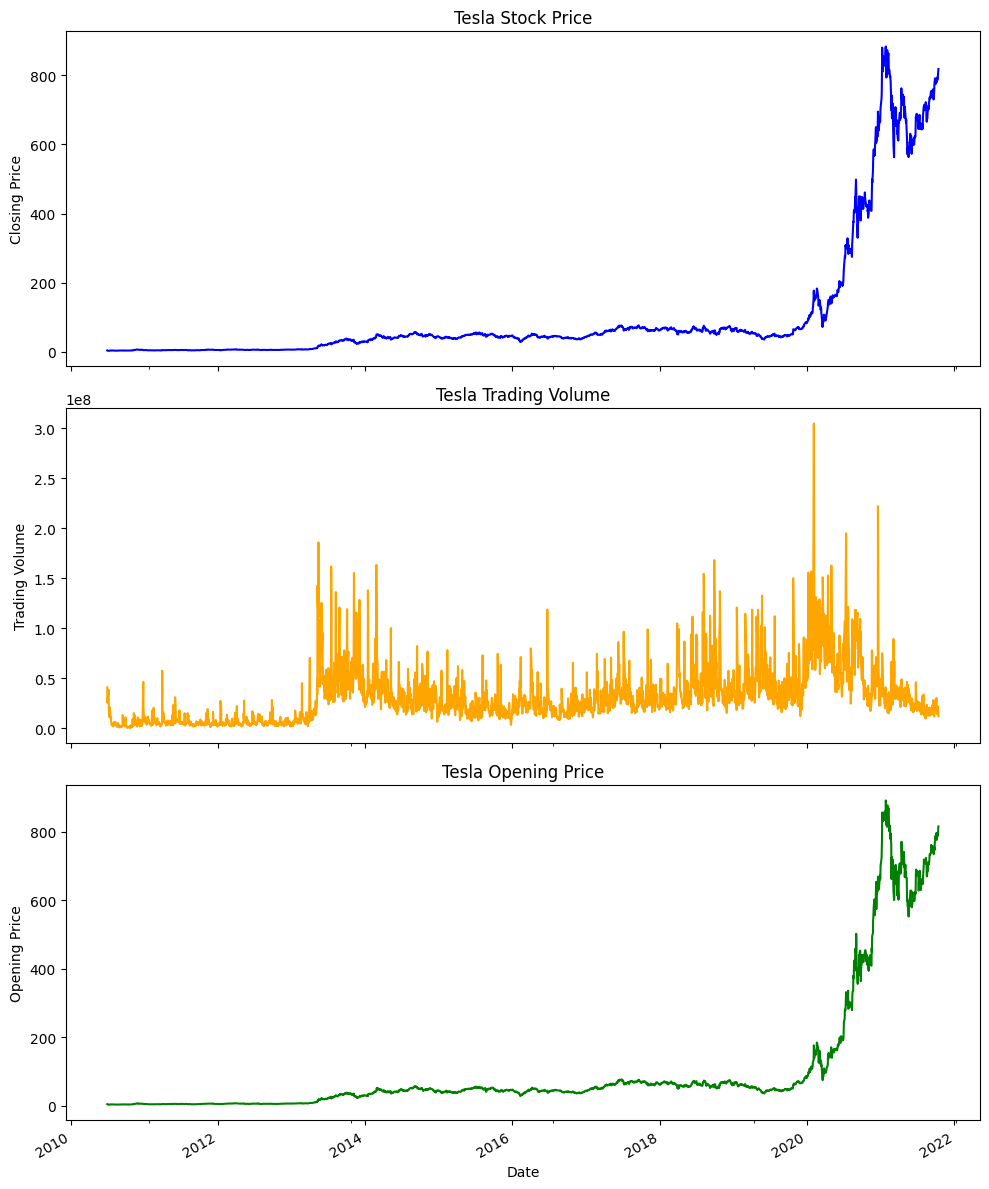

In [51]:
import matplotlib.pyplot as plt

# 1. Create the figure and axes subplots
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(10, 12), sharex=True)

# 2. Plot closing price
df['Close'].plot(ax=axes[0], title='Tesla Stock Price', color='blue')
axes[0].set_ylabel('Closing Price')

# 3. Plot volume
df['Volume'].plot(ax=axes[1], title='Tesla Trading Volume', color='orange')
axes[1].set_ylabel('Trading Volume')

# 4. Plot opening price
df['Open'].plot(ax=axes[2], title='Tesla Opening Price', color='green')
axes[2].set_ylabel('Opening Price')

# 5. Tighten layout and render the plots
plt.tight_layout()
plt.show()

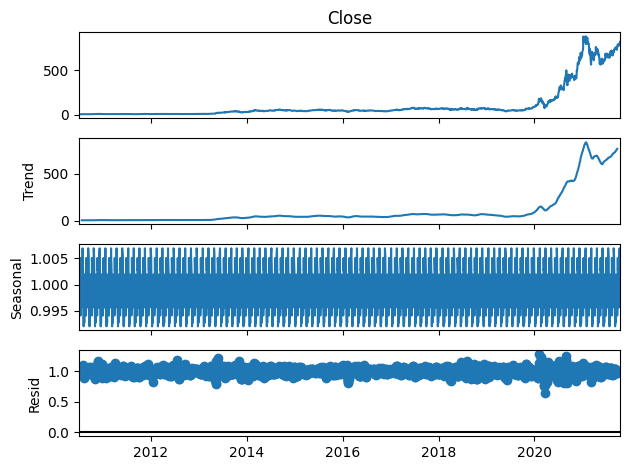

In [55]:
#seasonality analysis

decomposition=seasonal_decompose(df['Close'],model='multiplicative',period=30)
fig=decomposition.plot()
plt.show()

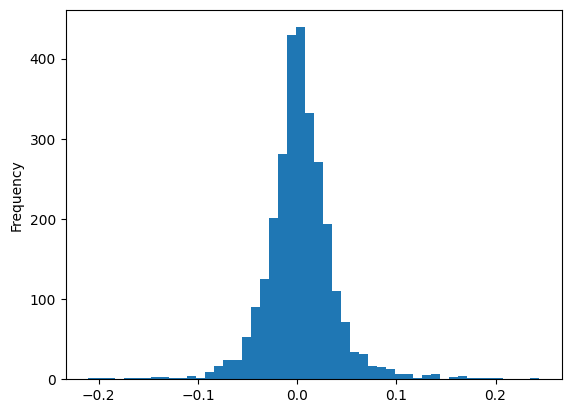

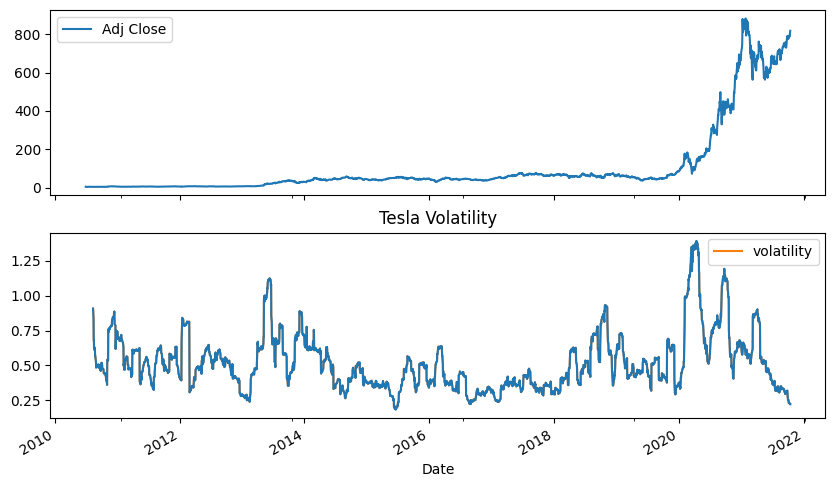

In [60]:
#volatility check
df['return']=df['Adj Close'].pct_change()
df['return'].plot(kind='hist',bins=50)
df['volatility']=df['return'].rolling(window=30).std()*np.sqrt(252)
df[['Adj Close','volatility']].plot(subplots=True,figsize=(10,6))
df['volatility'].plot(title='Tesla Volatility')
plt.show()

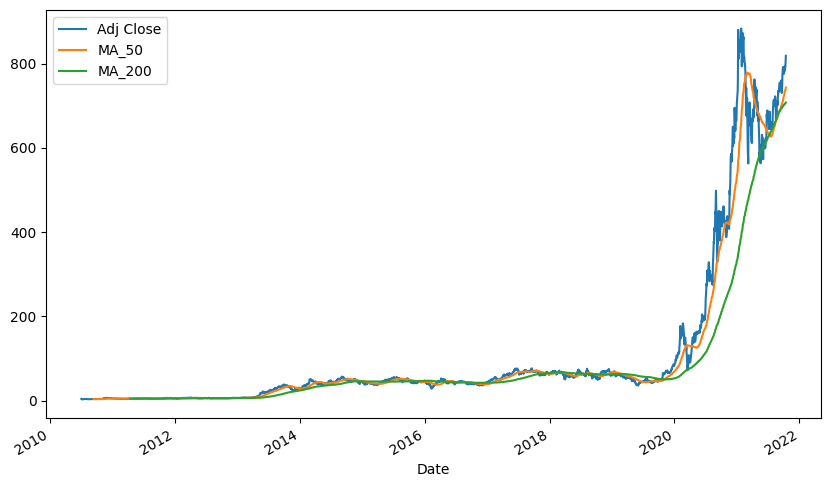

In [61]:
#Moving Average Analysis

df['MA_50']=df['Adj Close'].rolling(window=50).mean()
df['MA_200']=df['Adj Close'].rolling(window=200).mean()
df[['Adj Close','MA_50','MA_200']].plot(figsize=(10,6))
plt.show()

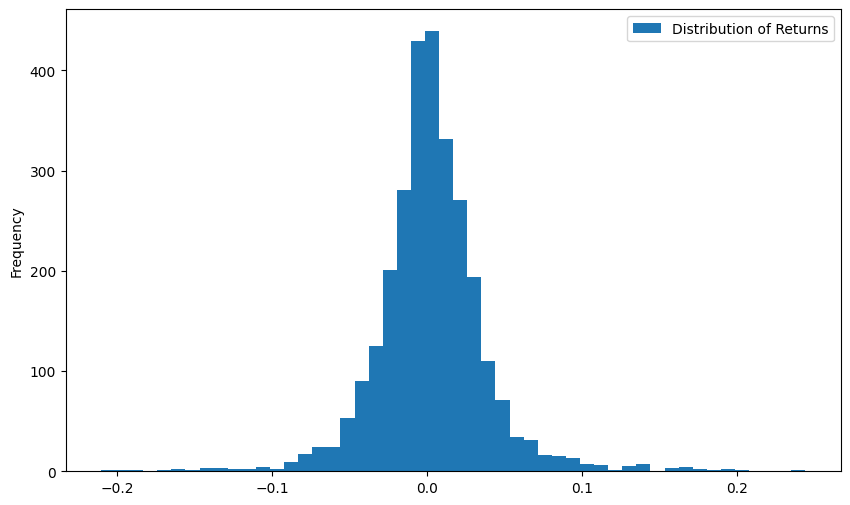

In [66]:
#Return Analysis
df['return']=df['Adj Close'].pct_change()
df['return'].plot(kind='hist',bins=50,figsize=(10,6),label='Distribution of Returns')
plt.legend()
plt.show()

In [70]:
#Prepare the data for facebook prophet

# Reset index safely
temp_df = df.reset_index()

# Check if we have 'ds' already, or if we need to rename 'Date'
if 'ds' in temp_df.columns:
    prophet_prep = temp_df[['ds', 'Close']].copy()
    prophet_prep.rename(columns={'Close': 'y'}, inplace=True)
elif 'Date' in temp_df.columns:
    prophet_prep = temp_df[['Date', 'Close']].copy()
    prophet_prep.rename(columns={'Date': 'ds', 'Close': 'y'}, inplace=True)
else:
    # Fallback to index if it represents date
    temp_df = temp_df.rename_axis('Date').reset_index()
    prophet_prep = temp_df[['Date', 'Close']].copy()
    prophet_prep.rename(columns={'Date': 'ds', 'Close': 'y'}, inplace=True)

prophet_prep.head(5)

,ds,y
0,2010-07-01,4.392
1,2010-07-02,3.840
2,2010-07-06,3.222
3,2010-07-07,3.160
4,2010-07-08,3.492


INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


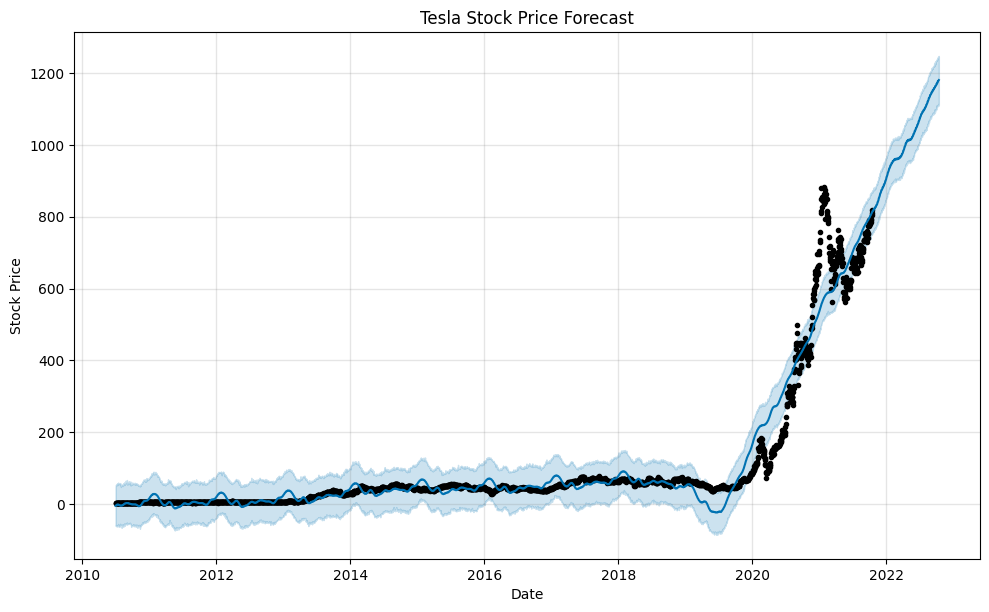

In [71]:
#Initialising the prophet model
model=Prophet()
model.fit(prophet_prep)
#specify the number of dates
future=model.make_future_dataframe(periods=365)
#use the model to make prediction
forecast=model.predict(future)
#visualise the forecast
model.plot(forecast)
plt.title('Tesla Stock Price Forecast')
plt.xlabel('Date')
plt.ylabel('Stock Price')
plt.show()